In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset
df = pd.read_csv("clean_data_after_eda.csv")

# Check the data
print(df.shape)
df.head()

(14606, 44)


,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,...,var_6m_price_off_peak_var,var_6m_price_peak_var,var_6m_price_mid_peak_var,var_6m_price_off_peak_fix,var_6m_price_peak_fix,var_6m_price_mid_peak_fix,var_6m_price_off_peak,var_6m_price_peak,var_6m_price_mid_peak,churn
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,...,0.000131,4.100838e-05,9.084737e-04,2.086294,99.530517,44.235794,2.086425,9.953056e+01,4.423670e+01,1
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,...,0.000003,1.217891e-03,0.000000e+00,0.009482,0.000000,0.000000,0.009485,1.217891e-03,0.000000e+00,0
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,...,0.000004,9.450150e-08,0.000000e+00,0.000000,0.000000,0.000000,0.000004,9.450150e-08,0.000000e+00,0
3,bba03439a292a1e166f80264c16191cb,lmkebamcaaclubfxadlmueccxoimlema,1584,0,0,2010-03-30,2016-03-30,2010-03-30,2015-03-31,240.04,...,0.000003,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000003,0.000000e+00,0.000000e+00,0
4,149d57cf92fc41cf94415803a877cb4b,MISSING,4425,0,526,2010-01-13,2016-03-07,2010-01-13,2015-03-09,445.75,...,0.000011,2.896760e-06,4.860000e-10,0.000000,0.000000,0.000000,0.000011,2.896760e-06,4.860000e-10,0


In [3]:
date_columns = [
    "date_activ",
    "date_end",
    "date_modif_prod",
    "date_renewal"
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors="coerce")

df[date_columns].dtypes

date_activ         datetime64[ns]
date_end           datetime64[ns]
date_modif_prod    datetime64[ns]
date_renewal       datetime64[ns]
dtype: object

In [4]:
df["price_off_peak_yearly_change"] = df["var_year_price_off_peak_var"]

df[["price_off_peak_yearly_change", "churn"]].head()

,price_off_peak_yearly_change,churn
0,0.000061,1
1,0.000005,0
2,0.000006,0
3,0.000005,0
4,0.000015,0


In [5]:
# Difference between 6-month and yearly off-peak price variation
df["off_peak_price_momentum"] = (
    df["var_6m_price_off_peak_var"] -
    df["var_year_price_off_peak_var"]
)

# Overall yearly variable-price change
df["total_year_price_var"] = (
    df["var_year_price_off_peak_var"] +
    df["var_year_price_peak_var"] +
    df["var_year_price_mid_peak_var"]
)

# Overall 6-month variable-price change
df["total_6m_price_var"] = (
    df["var_6m_price_off_peak_var"] +
    df["var_6m_price_peak_var"] +
    df["var_6m_price_mid_peak_var"]
)

# Absolute price changes
df["abs_year_price_change"] = (
    df["var_year_price_off_peak_var"].abs() +
    df["var_year_price_peak_var"].abs() +
    df["var_year_price_mid_peak_var"].abs()
)

# Fixed-price variation
df["total_year_fixed_price_change"] = (
    df["var_year_price_off_peak_fix"] +
    df["var_year_price_peak_fix"] +
    df["var_year_price_mid_peak_fix"]
)

df["total_6m_fixed_price_change"] = (
    df["var_6m_price_off_peak_fix"] +
    df["var_6m_price_peak_fix"] +
    df["var_6m_price_mid_peak_fix"]
)

In [6]:
# Consumption change from last month relative to yearly consumption
df["monthly_consumption_ratio"] = (
    df["cons_last_month"] /
    (df["cons_12m"] + 1)
)

# Gas consumption as a proportion of total consumption
df["gas_consumption_ratio"] = (
    df["cons_gas_12m"] /
    (df["cons_12m"] + 1)
)

# Forecast error / difference
df["forecast_consumption_difference"] = (
    df["forecast_cons_12m"] -
    df["cons_12m"]
)

# Forecast-to-actual consumption ratio
df["forecast_consumption_ratio"] = (
    df["forecast_cons_12m"] /
    (df["cons_12m"] + 1)
)

# Margin per active product
df["margin_per_product"] = (
    df["net_margin"] /
    (df["nb_prod_act"] + 1)
)

In [7]:
# Customer tenure in months
df["tenure_months"] = (
    (df["date_end"] - df["date_activ"]).dt.days / 30.44
)

# Months since product modification
df["months_since_product_change"] = (
    (df["date_end"] - df["date_modif_prod"]).dt.days / 30.44
)

# Months since renewal
df["months_since_renewal"] = (
    (df["date_end"] - df["date_renewal"]).dt.days / 30.44
)

In [8]:
new_features = [
    "price_off_peak_yearly_change",
    "off_peak_price_momentum",
    "total_year_price_var",
    "total_6m_price_var",
    "abs_year_price_change",
    "total_year_fixed_price_change",
    "total_6m_fixed_price_change",
    "monthly_consumption_ratio",
    "gas_consumption_ratio",
    "forecast_consumption_difference",
    "forecast_consumption_ratio",
    "margin_per_product",
    "tenure_months",
    "months_since_product_change",
    "months_since_renewal"
]

correlation = df[new_features + ["churn"]].corr()["churn"].sort_values(ascending=False)

print(correlation)

churn                              1.000000
forecast_consumption_difference    0.046059
margin_per_product                 0.037933
price_off_peak_yearly_change       0.028646
total_year_price_var               0.021258
abs_year_price_change              0.021258
total_year_fixed_price_change      0.018099
total_6m_price_var                 0.015901
total_6m_fixed_price_change        0.013350
months_since_renewal               0.001842
gas_consumption_ratio             -0.000584
forecast_consumption_ratio        -0.002198
monthly_consumption_ratio         -0.009100
off_peak_price_momentum           -0.012229
months_since_product_change       -0.053321
tenure_months                     -0.073919
Name: churn, dtype: float64


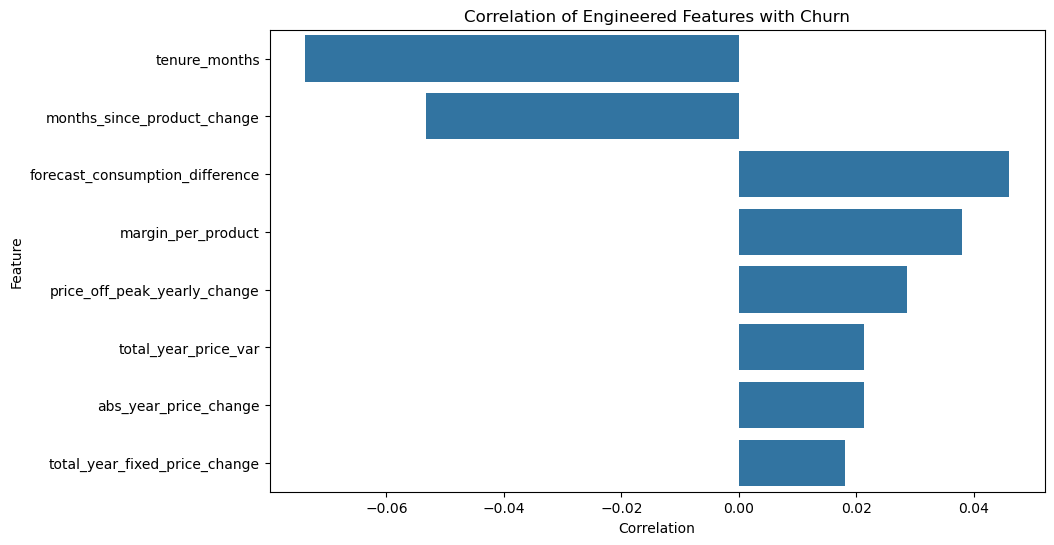

In [9]:
top_features = correlation.drop("churn").abs().sort_values(ascending=False).head(8).index

plt.figure(figsize=(10, 6))
sns.barplot(
    x=correlation[top_features].values,
    y=top_features
)

plt.title("Correlation of Engineered Features with Churn")
plt.xlabel("Correlation")
plt.ylabel("Feature")
plt.show()

In [10]:
df_model = df.drop(columns=["id"])

print(df_model.shape)
df_model.head()

(14606, 58)


,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,forecast_cons_year,...,total_year_fixed_price_change,total_6m_fixed_price_change,monthly_consumption_ratio,gas_consumption_ratio,forecast_consumption_difference,forecast_consumption_ratio,margin_per_product,tenure_months,months_since_product_change,months_since_renewal
0,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,0,...,72.676023,145.852604,0.000000,54946.0,0.00,0.000000,226.330,36.005256,7.457293,11.760841
1,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,0,...,0.006465,0.009482,0.000000,0.0,-4470.05,0.040753,9.445,84.296978,84.296978,11.990802
2,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,0,...,0.007662,0.000000,0.000000,0.0,-496.04,0.088000,3.300,72.010512,72.010512,11.990802
3,lmkebamcaaclubfxadlmueccxoimlema,1584,0,0,2010-03-30,2016-03-30,2010-03-30,2015-03-31,240.04,0,...,0.006465,0.000000,0.000000,0.0,-1343.96,0.151445,12.730,72.010512,72.010512,11.990802
4,MISSING,4425,0,526,2010-01-13,2016-03-07,2010-01-13,2015-03-09,445.75,526,...,0.008252,0.000000,0.118843,0.0,-3979.25,0.100712,23.990,73.751643,73.751643,11.957950


In [11]:
df_model.to_csv("engineered_features.csv", index=False)

print("Engineered dataset saved successfully.")

Engineered dataset saved successfully.
